# Integrative Industry Synthesis: ML, GenAI, and Agentic
- Simulation

# Setup

## Import required modules

In [1]:
from pathlib import Path
import time
import sys
SRC_DIR = str(Path.cwd().parent /'src')
if SRC_DIR not in sys.path:
    sys.path.append(SRC_DIR)
notebook_start_time = time.time() # Start the global timer
print(f'notebook_start_time={time.ctime(notebook_start_time)}')

notebook_start_time=Fri Oct  2 14:39:03 2026


In [2]:
import importlib
from config import settings
import utils as ut #use importlib.reload(ut) if reload needed in specific cell during development
import utils_gen as ut_gen
import seaborn as sns
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib # for version check
import matplotlib.pyplot as plt
import torch
from collections import Counter
import joblib
from tqdm.notebook import tqdm

from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
# Enable high-resolution Retina plots
%config InlineBackend.figure_format = 'retina'

In [3]:
print("*" * 75)
print(f'PYTHON VERSION:      {sys.version}')
print(f'PYTHON VPATH:        {sys.executable}')
print(f"Pandas version:      {pd.__version__}")
print(f"NumPy version:       {np.__version__}")
print(f"Matplotlib version:  {matplotlib.__version__}")
print(f"Seaborn version:     {sns.__version__}")
print("*" * 75)

***************************************************************************
PYTHON VERSION:      3.13.14 (main, Jul 23 2026, 14:44:45) [Clang 22.1.3 ]
PYTHON VPATH:        /home/max/x/zc07-ml-genai-agentic/.venv/bin/python
Pandas version:      2.3.3
NumPy version:       2.5.3
Matplotlib version:  3.11.2
Seaborn version:     0.13.2
***************************************************************************


In [4]:
print(f'Torch version: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
print(f'CUDA version used: {torch.version.cuda}')

Torch version: 2.14.1+cu130
CUDA available: True
CUDA version used: 13.0


In [5]:
def seed_all(seed:int=42):
    """
    set random seed and cuda related settings for reproducibility
    Args:
        seed: int setting the seed
    Return:
        None
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
#---------------------------------------------
seed_all(settings.RANDOM_SEED)

# Load Cleaned Dataset

In [6]:
df = pd.read_csv(settings.DATA_DIR/settings.DATASET_FILE_CLEANED)
df=ut.remove_duplicate(df) # based on step2-analysis, we know we have some duplicates due to converting time to Hour then to Hour//2
L=len(df)
df.sample(1)

number of rows Before and After removing duplicates: Before = 283726,  After = 280286


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Hour/2
181582,-1.356781,0.757238,-0.519152,-3.029253,-0.29847,1.447223,-2.830482,-5.374117,-1.369903,1.76085,-0.45979,-0.020525,0.834609,-0.456194,-1.301488,0.072788,0.095017,1.014156,0.159065,-1.510688,5.31388,-1.594007,0.23972,-0.384012,-0.769955,-0.281715,0.29511,0.167094,13.8,0,5


In [7]:
df0=df[df.Class==0].reset_index(drop=True).copy()
L0=len(df0)

In [8]:
df1=df[df.Class==1].reset_index(drop=True).copy()
L1=len(df1)

In [9]:
print(f'Legit-Class count: L0={L0}, Fraud-Class count L1={L1}, ratio={L0/L1:.1f}')
print(f'Legit%-Fraud%: {L0/L:.2%}-{L1/L:.2%}')

Legit-Class count: L0=279813, Fraud-Class count L1=473, ratio=591.6
Legit%-Fraud%: 99.83%-0.17%


# Load Classifier Model
- Load our Classifier model: XGBoost with Fraud class over-sampled using CTGAN generative model (only trained on training data)

In [10]:
clf_model = joblib.load(settings.MODEL_DIR/'XGB_CTGAN_model.pkl')

# Load Generative Model
- Load our selected generative models for both Fraud and Legitimate 
- Generate same number of samples as in the original data for both classes

In [11]:
extF='_F' # extension used for generative model to show full dataset was used for training
gen_model_dic={}
# when we have the model, first arg can be empty data-frame (wont be used anyway)
gen_model_dic['CTGAN0'] = ut_gen.get_model_for_synthesizer(pd.DataFrame(), class_label=0, synthesizer='ctgan', ext=extF)
gen_model_dic['CTGAN1'] = ut_gen.get_model_for_synthesizer(pd.DataFrame(), class_label=1, synthesizer='ctgan', ext=extF)

df_columns = pd.read_csv(settings.DATA_DIR/settings.DATASET_FILE_CLEANED, nrows=0).columns
feature_cols = [c for c in df_columns if c != 'Class']
#sample-call-to generate
dfc0 = ut_gen.get_sample_form_synthesizer(gen_model_dic['CTGAN0'], num_rows=L0, feature_cols=feature_cols, class_label=0, synthesizer='ctgan', ext=extF)
dfc1 = ut_gen.get_sample_form_synthesizer(gen_model_dic['CTGAN1'], num_rows=L1, feature_cols=feature_cols, class_label=1, synthesizer='ctgan', ext=extF)
dfc=pd.concat([dfc0,dfc1])

Loading CTGAN model for majority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/ctgan_majority_model_F.pkl
Loading CTGAN model for minority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/ctgan_minority_model_F.pkl
Loading CTGAN Scaler for majority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/ctgan_majority_scaler_F.pkl
Start Generating 279813 samples ...
Loading CTGAN Scaler for minority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/ctgan_minority_scaler_F.pkl
Start Generating 473 samples ...


# Select Threshold for Anomaly (Fraud) Detection

In [12]:
# def get_optimal_thr(clf, df, tag, th_list_log=np.linspace(-5,-0.01,200)):
#     """
#     A helper function to calculate optimal threshold for maximizing F2-Score
#     and providing data for plotting all 
#     Args:
#         - clf: classifier model
#         - df: dataframe contains data for test with target column called 'Class'
#         - tag: name for tracking
#         - th_list_log: list of threshold for test in log10 format
#     Returns:
#         dataframe for plotting, optimal-threshold, and list of metrics for optimal threshold and 0.5 thresold
#     """
#     y_test= df['Class']
#     X_test = df.drop(columns=['Class'])
#     #th_list_log=np.linspace(-5,-0.01,200)
#     th_list=np.power(10,th_list_log)
#     metrics=[]
#     for th in tqdm(th_list,'Thr'):
#         metrics.append(ut.get_model_scores(X_test, y_test, 'Test', clf, th))
#     metrics_df=pd.DataFrame(metrics)
#     idx_max = metrics_df['F2-Score'].idxmax()
#     thx=metrics_df.loc[idx_max,'Threshold']
#     metrics_df['Threshold_log10']=np.log10(metrics_df['Threshold'])
#     metrics_df=metrics_df.drop(columns=['Model', 'Threshold'])
#     metrics2=[]
#     for th in [thx,0.1, 0.15, 0.5, 0.85]: # selected thresholds !
#         metrics2.append(ut.get_model_scores(X_test, y_test, tag, clf, th))
#     print(f'Maximizing F2-Score: Optimal Threshold= {thx:.4f} (log10= {np.log10(thx):.3f})')
#     return metrics_df, thx, metrics2

In [13]:
metrics_df, thx , metrics2= ut.get_optimal_thr(clf_model, df,'Real_Data', th_list_log=np.linspace(-5,-0.01,100) )

Thr:   0%|          | 0/100 [00:00<?, ?it/s]

Maximizing F2-Score: Optimal Threshold= 0.0959 (log10= -1.018)


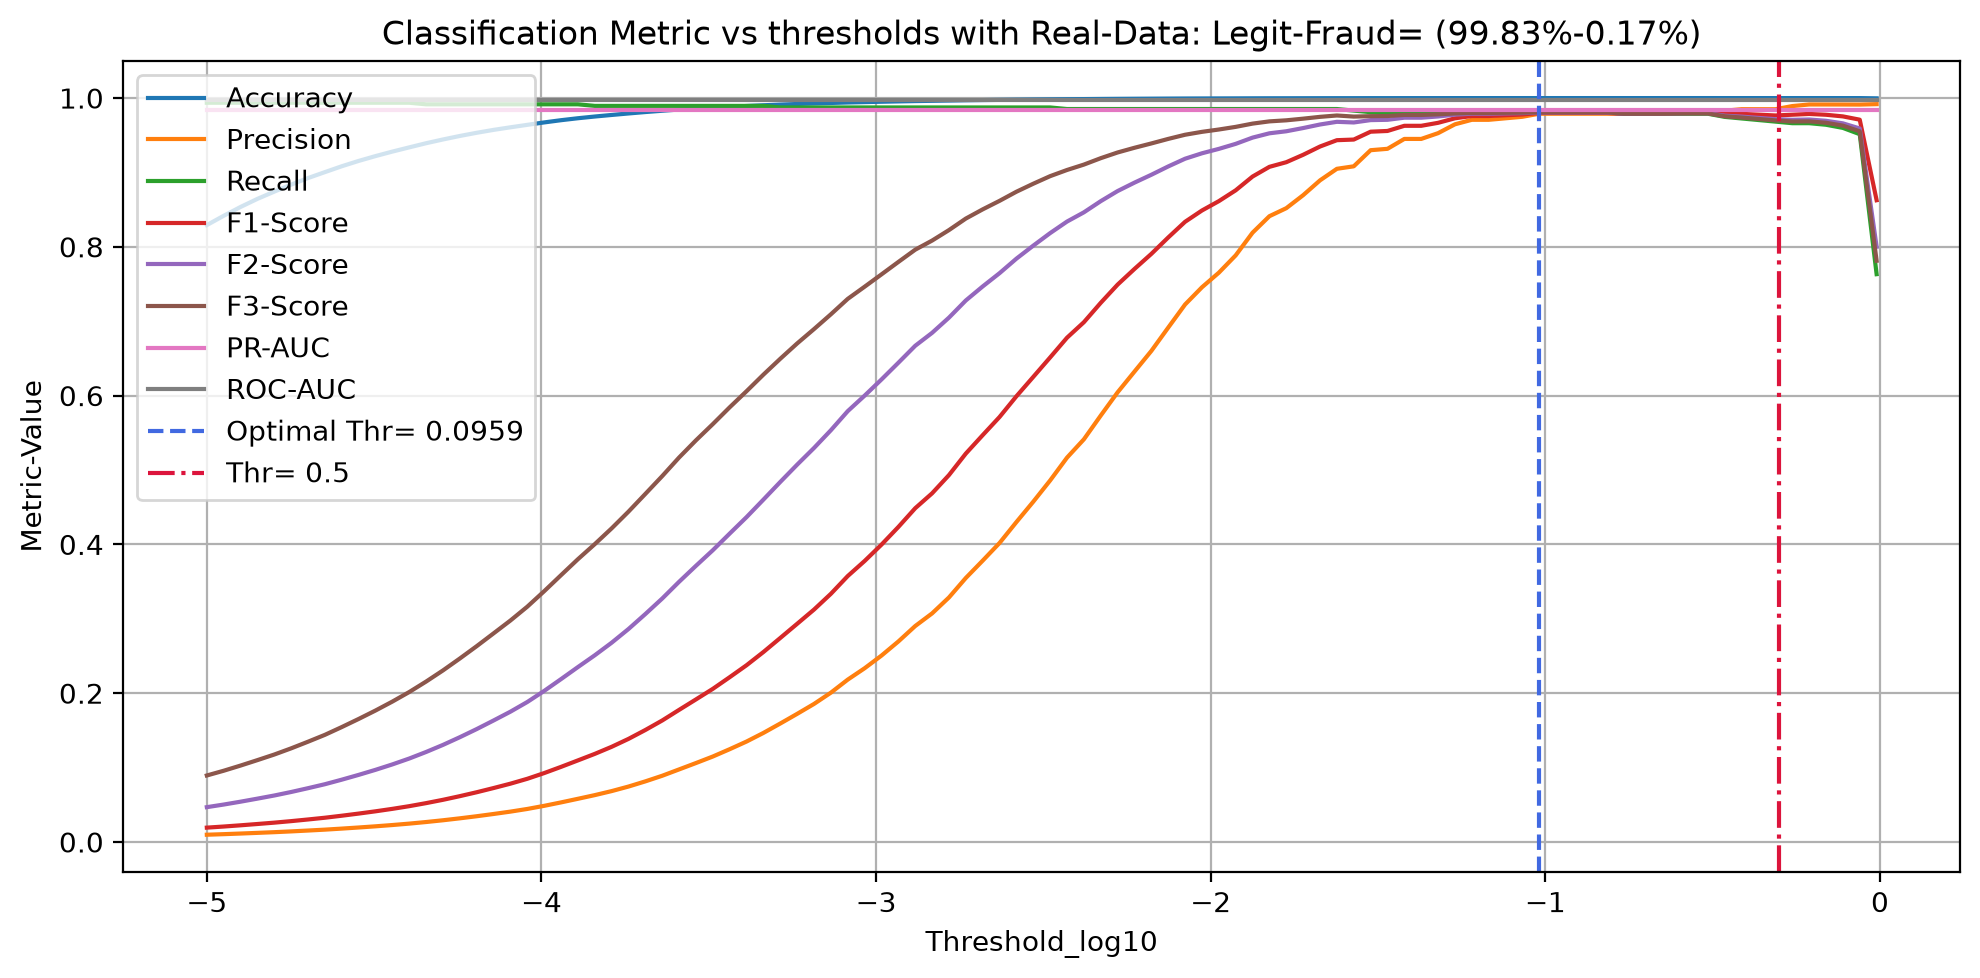

In [14]:
ax=metrics_df.plot(x='Threshold_log10', figsize=(10,5), grid=True, ylabel='Metric-Value', title=f'Classification Metric vs thresholds with Real-Data: Legit-Fraud= ({L0/L:.2%}-{L1/L:.2%})')
ax.axvline(x=np.log10(thx),color='royalblue', linestyle='--', linewidth=1.5, label=f'Optimal Thr= {thx:.4f}')
ax.axvline(x=np.log10(0.5),color='crimson', linestyle='-.', linewidth=1.5, label=f'Thr= {0.5:.1f}')
ax.legend(loc='upper left');
plt.tight_layout()
plt.savefig(settings.IMG_DIR/'metric_thr_real_data.png', dpi=600)

In [15]:
metrics_dfc, thxc , metrics2c= ut.get_optimal_thr(clf_model, dfc,'Gen_Data', th_list_log=np.linspace(-5,-0.01,100) )

Thr:   0%|          | 0/100 [00:00<?, ?it/s]

Maximizing F2-Score: Optimal Threshold= 0.0603 (log10= -1.220)


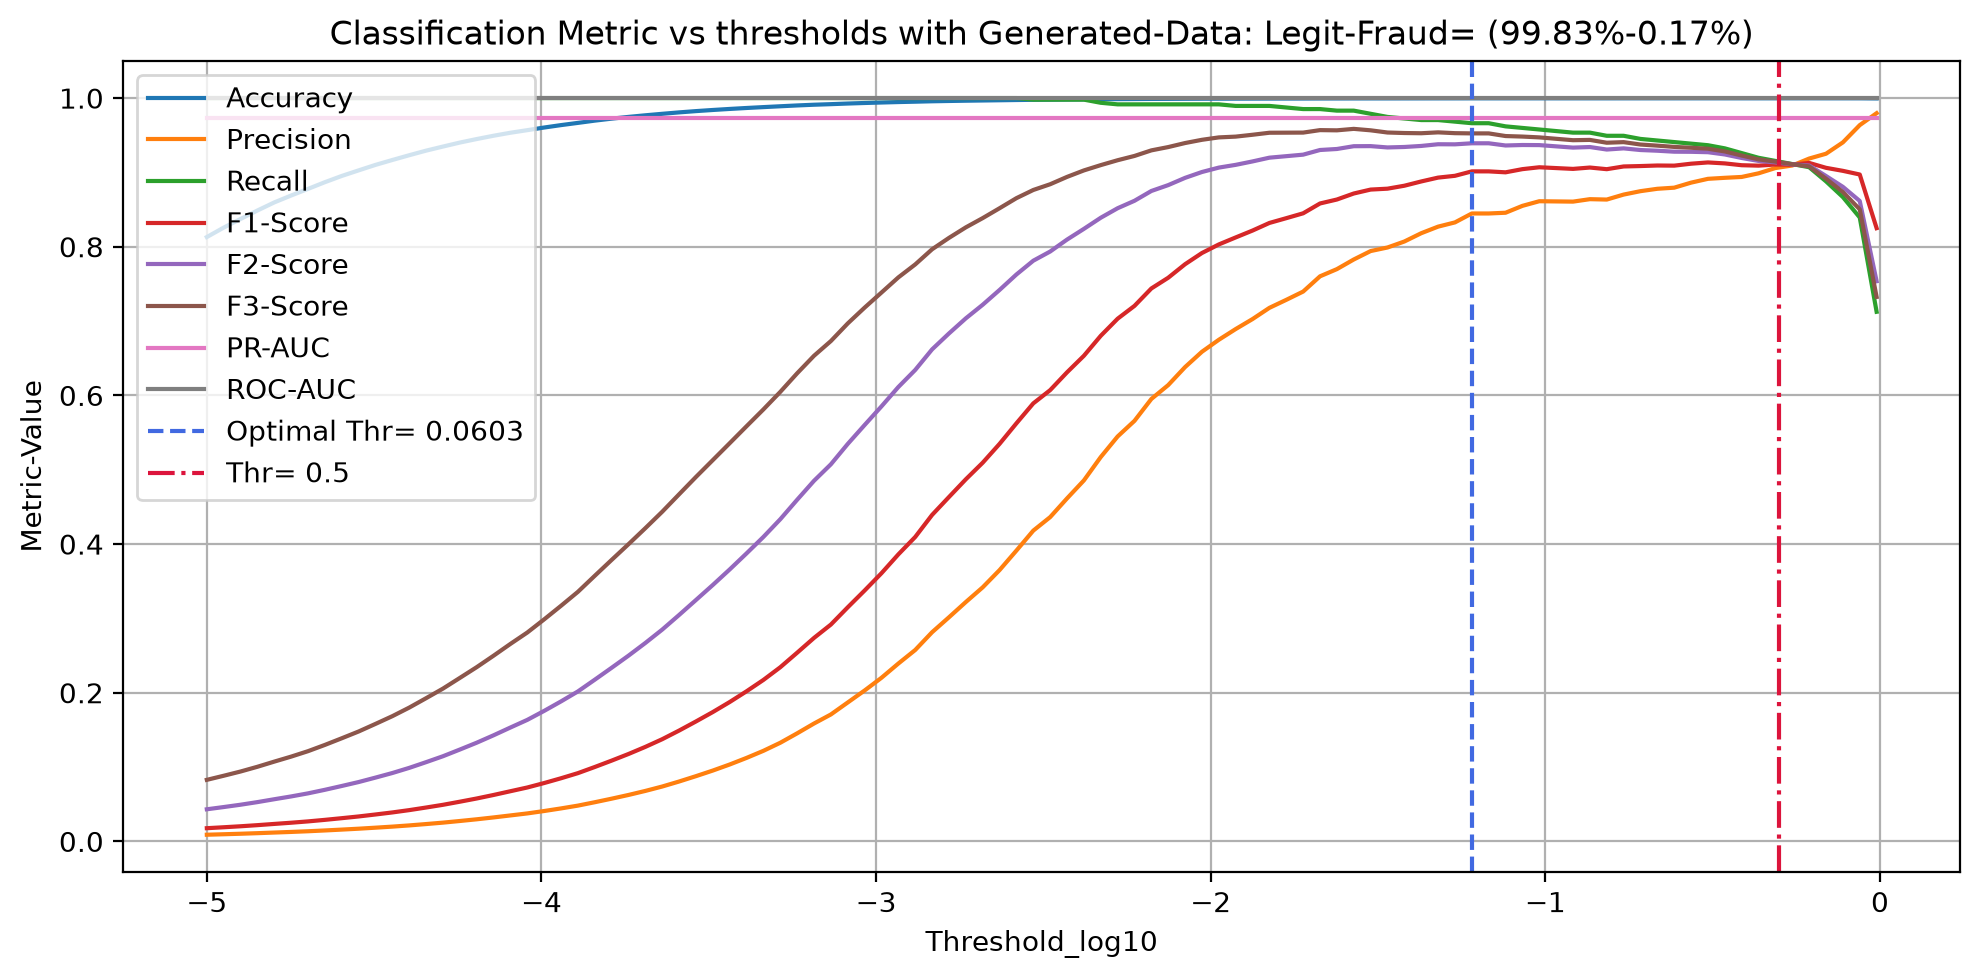

In [16]:
ax=metrics_dfc.plot(x='Threshold_log10', figsize=(10,5), grid=True, ylabel='Metric-Value', title=f'Classification Metric vs thresholds with Generated-Data: Legit-Fraud= ({L0/L:.2%}-{L1/L:.2%})')
ax.axvline(x=np.log10(thxc),color='royalblue', linestyle='--', linewidth=1.5, label=f'Optimal Thr= {thxc:.4f}')
ax.axvline(x=np.log10(0.5),color='crimson', linestyle='-.', linewidth=1.5, label=f'Thr= {0.5:.1f}')
ax.legend(loc='upper left');
plt.tight_layout()
plt.savefig(settings.IMG_DIR/'metric_thr_gen_data.png', dpi=600)

## Question
- __How this optimal may change if we have 50%-50% of Legit-Fraud instead of real data with 99.83%-0.17% proportion?__
- We check this as information
- We will use threshold based on real data proportion

In [17]:
LL = 50000
dfc0 = ut_gen.get_sample_form_synthesizer(gen_model_dic['CTGAN0'], num_rows=LL, feature_cols=feature_cols, class_label=0, synthesizer='ctgan', ext=extF)
dfc1 = ut_gen.get_sample_form_synthesizer(gen_model_dic['CTGAN1'], num_rows=LL, feature_cols=feature_cols, class_label=1, synthesizer='ctgan', ext=extF)
dfcLL=pd.concat([dfc0,dfc1])

Loading CTGAN Scaler for majority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/ctgan_majority_scaler_F.pkl
Start Generating 50000 samples ...
Loading CTGAN Scaler for minority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/ctgan_minority_scaler_F.pkl
Start Generating 50000 samples ...


In [18]:
metrics_dfcLL, thxcLL , metrics2cLL= ut.get_optimal_thr(clf_model, dfcLL,'Gen_Data', th_list_log=np.linspace(-5,-0.01,100) )

Thr:   0%|          | 0/100 [00:00<?, ?it/s]

Maximizing F2-Score: Optimal Threshold= 0.0007 (log10= -3.135)


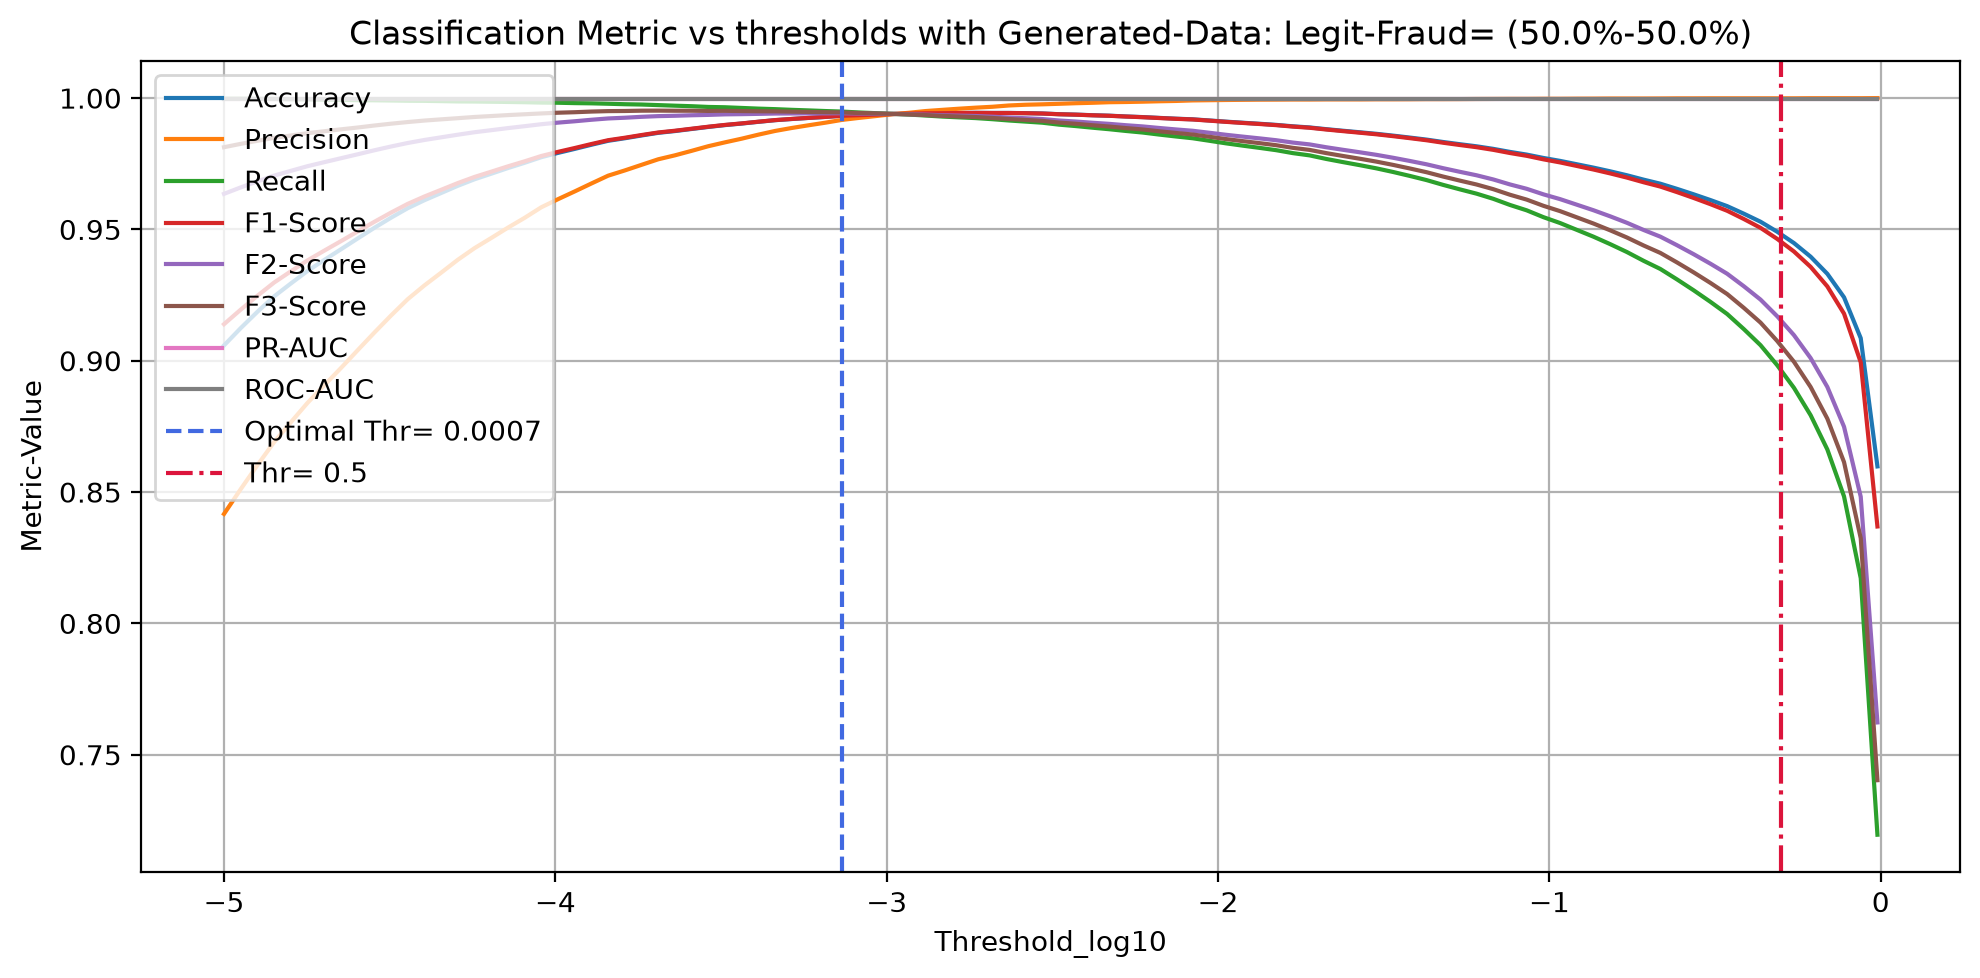

In [19]:
ax=metrics_dfcLL.plot(x='Threshold_log10', figsize=(10,5), grid=True, ylabel='Metric-Value', title=f'Classification Metric vs thresholds with Generated-Data: Legit-Fraud= ({1/2:.1%}-{1/2:.1%})')
ax.axvline(x=np.log10(thxcLL),color='royalblue', linestyle='--', linewidth=1.5, label=f'Optimal Thr= {thxcLL:.4f}')
ax.axvline(x=np.log10(0.5),color='crimson', linestyle='-.', linewidth=1.5, label=f'Thr= {0.5:.1f}')
ax.legend(loc='upper left');
plt.tight_layout()
plt.savefig(settings.IMG_DIR/'metric_thr_gen_data_5050.png', dpi=600)

### Note
- Seems proportaion of Legit-Fraud can affect the optimal thresold
- But we will use real-data proportion for selecting threshold

In [20]:
metrics2_df=pd.DataFrame(metrics2+metrics2c)
metrics2_df.set_index('Model', inplace=True)
metrics2_df=metrics2_df[metrics2_df.Threshold != 0.5]
metrics2_df=(100*metrics2_df).round(3)
metrics2_df.Threshold = metrics2_df.Threshold/100
metrics2_df

,Threshold,Accuracy,Precision,Recall,F1-Score,F2-Score,F3-Score,PR-AUC,ROC-AUC
Model,,,,,,,,,
Real_Data,0.09592,99.993,97.890,98.097,97.994,98.056,98.077,98.331,99.668
Real_Data,0.10000,99.993,97.890,98.097,97.994,98.056,98.077,98.331,99.668
Real_Data,0.15000,99.993,97.890,98.097,97.994,98.056,98.077,98.331,99.668
Real_Data,0.85000,99.991,99.121,95.349,97.198,96.080,95.713,98.331,99.668
Gen_Data,0.06030,99.964,84.473,96.617,90.138,93.917,95.248,97.371,99.995
Gen_Data,0.10000,99.967,86.122,95.772,90.691,93.672,94.710,97.371,99.995
Gen_Data,0.15000,99.966,86.346,94.926,90.433,93.076,93.992,97.371,99.995
Gen_Data,0.85000,99.969,96.163,84.778,90.112,86.834,85.794,97.371,99.995


## NOTE on Single Threshold vs Dual Thresholds
- We evaluated all metrics on both real data and generated data
- To maximize F2-Score, we have thresholds of `0.096` on Real-Data and `0.060` on Generated Data.
- Rounding this threshold to 1 decimal points we get the same `0.1` threshold, and we __may__ use this as a single threshold

However, in an agentic workflow, we can use 2 thresholds for example, as a **Triage** stage The classifier-model in anomaly/fraud detection-node  calculates initial probability $p(\text{fraud})$.
* $p < 0.15 \rightarrow$ **Auto-Approve**
* $p > 0.85 \rightarrow$ **Auto-Block** & Write to LTM as `FRAUD_CONFIRMED`
* $0.15 \le p \le 0.85 \rightarrow$ **Escalate to Agent**


## Question: - How we can find these 2 thresholds based on our data?
- This will be a 2D optimization problem
- We need to define some costs and then find low ($\tau\_{low}$) and high ($\tau\_{high}$) thresholds
- Similar to F2-Score on single threshold we consider the cost for False-Negative (FN) twice the cost for False-Positive (FP) due to nature of the consequence for the business as discussed before (in step-1)
- Also we need to consider a cost for LLM-agent involvement in the process if Fraud detector could not auto-resolve
- Finally there will be a cost due to accuracy of LLM-agent
- While selecting these parameter needs many practical consideration in the real production setup, here we simply assume
   1. Cost of FN: `10.0`
   2. cost of FP: `5.0`
   3. cost of using LLM-Agent: `0.2`
   4. LLM-Agent accuracy: `90%`

In [59]:
th_log = np.linspace(-5, -0.01, 100)
best_tau_low, best_tau_high, result_df, Tau_Low_Log, Tau_High_Log, cost_surface = \
ut.find_optimal_triage_thresholds(clf_model, df, th_list_log=th_log, c_fn=10.0, c_fp=5.0, c_agent=0.2, agent_accuracy=0.90)
print(f'Optimal: low={best_tau_low:.5f} (log10={np.log10(best_tau_low):.3f}), high={best_tau_high:.5f} (log10={np.log10(best_tau_high):.3f})')

Searching Log Thresholds:   0%|          | 0/100 [00:00<?, ?it/s]

Optimal: low=0.09592 (log10=-1.018), high=0.61430 (log10=-0.212)


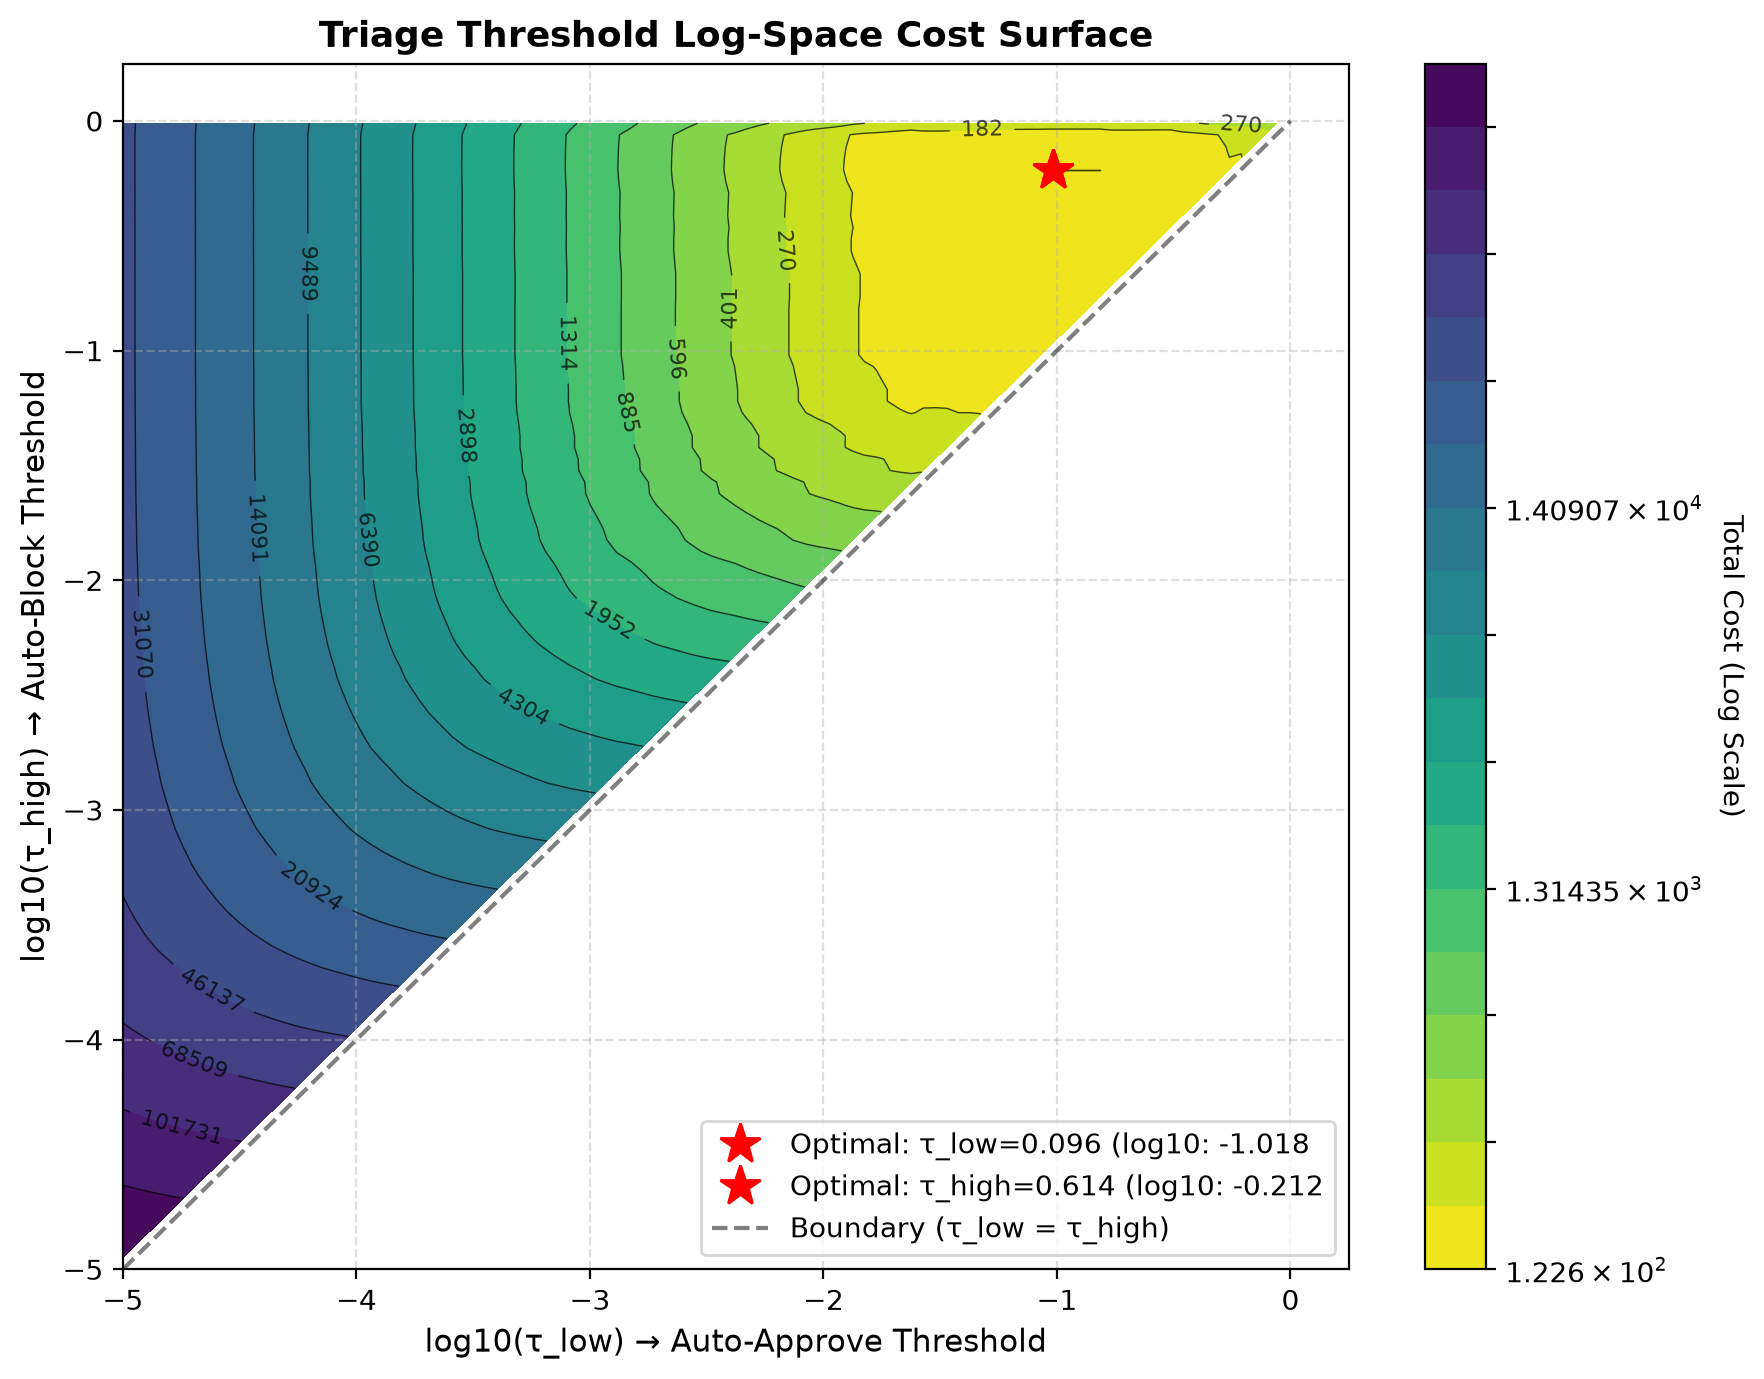

In [60]:
importlib.reload(ut)
ut.plot_optimal_triage_thresholds_contour(best_tau_low, best_tau_high, Tau_Low_Log, Tau_High_Log, cost_surface)

In [61]:
th_log = np.linspace(-5, -0.01, 100)
best_tau_low, best_tau_high, result_df, Tau_Low_Log, Tau_High_Log, cost_surface = \
ut.find_optimal_triage_thresholds(clf_model, dfc, th_list_log=th_log, c_fn=10.0, c_fp=5.0, c_agent=0.2, agent_accuracy=0.90)
print(f'Optimal: low={best_tau_low:.5f} (log10={np.log10(best_tau_low):.3f}), high={best_tau_high:.5f} (log10={np.log10(best_tau_high):.3f})')

Searching Log Thresholds:   0%|          | 0/100 [00:00<?, ?it/s]

Optimal: low=0.02676 (log10=-1.573), high=0.87015 (log10=-0.060)


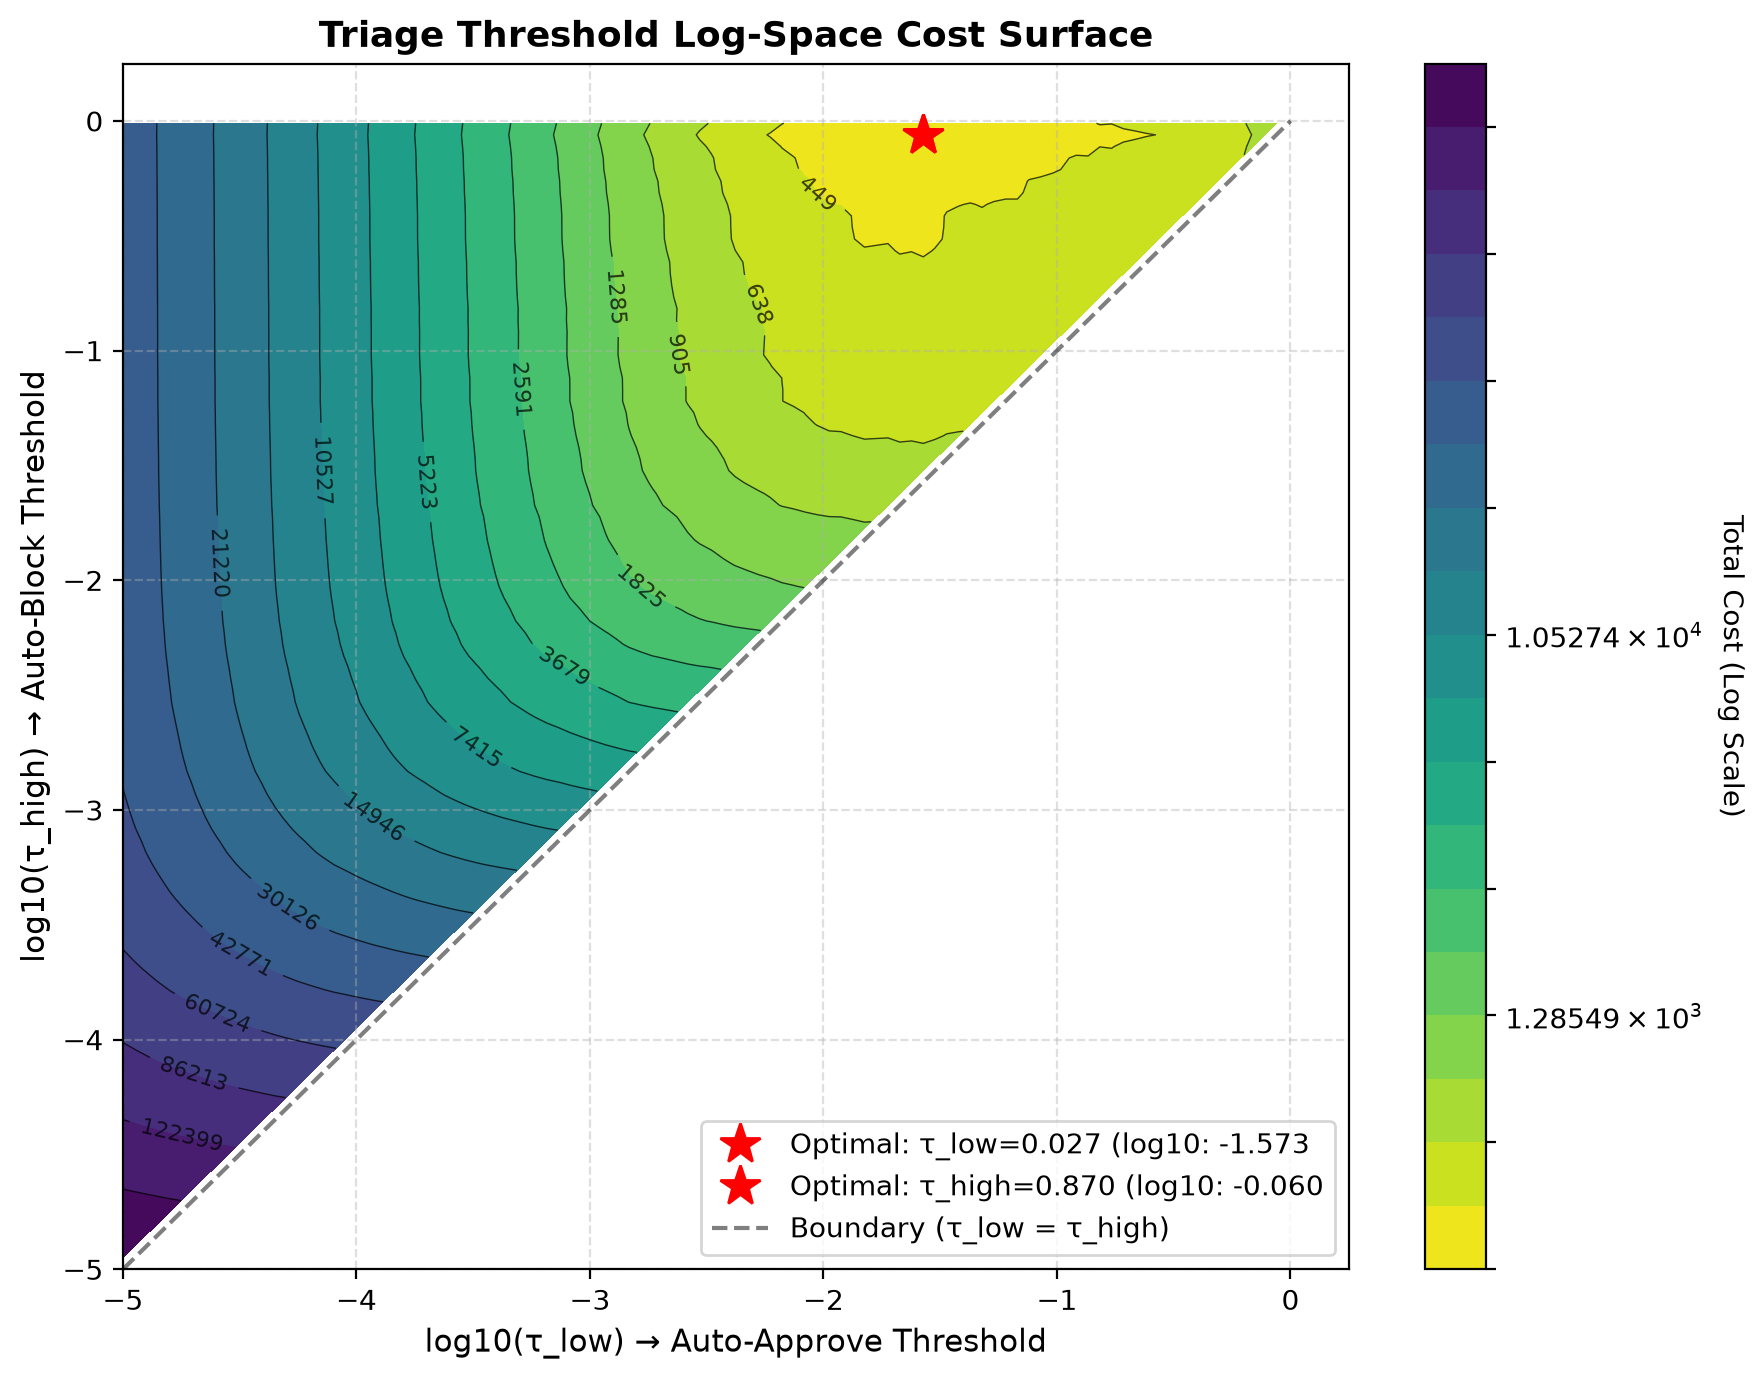

In [62]:
ut.plot_optimal_triage_thresholds_contour(best_tau_low, best_tau_high, Tau_Low_Log, Tau_High_Log, cost_surface)

In [65]:
y_test = dfc['Class'].values
X_test = dfc.drop(columns=['Class'])
metrics_dual_th=[]
for th in [best_tau_low, best_tau_high]:
    metrics_dual_th.append(ut.get_model_scores(X_test, y_test, 'Gen', clf_model, th))
pd.DataFrame(metrics_dual_th)

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,F2-Score,F3-Score,PR-AUC,ROC-AUC
0,Gen,0.026759,0.999511,0.782828,0.983087,0.871603,0.935237,0.958565,0.973715,0.999947
1,Gen,0.870154,0.999675,0.963592,0.839323,0.897175,0.861545,0.850289,0.973715,0.999947


In [67]:
print(list(df.columns))

['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class', 'Hour/2']


In [68]:
sys.exit(0)

SystemExit: 0

/home/max/x/zc07-ml-genai-agentic/.venv/lib/python3.13/site-packages/IPython/core/interactiveshell.py:3831: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
TH=0.85

# Vector database

In [ ]:
from sklearn.metrics import confusion_matrix
def plot_confusion_matrix(clf, df, thr, tag, sns_cmap, ext_ax):
    """
    A helper function to plot Confusion Matrix and return y_true and y_pred    
    Args:
        - clf: classifier model
        - df: dataframe contains data for test with target column called 'Class'
        - thr: thresold use in prediction probability of class-1
        - tag: name for tracking
        - sns_cmap: map used for plotting
        - ext_ax: axis for plot
    Returns:
        y_true and y_pred
    """
    y_test= df['Class']
    X_test = df.drop(columns=['Class'])
    y_probs = clf.predict_proba(X_test)[:, 1]
    y_pred = (y_probs >= thr).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    cm_xytick=['Not-Fraud', 'Fraud'] # Confusion matrix xy tick label
    sns.heatmap(cm, annot=True, fmt='d', cmap=sns_cmap, xticklabels=cm_xytick, yticklabels=cm_xytick, ax=ext_ax, annot_kws={'size': 16})
    ext_ax.set_title(f'{tag}: Confusion Matrix (Thr: {thr:.2f})', fontsize=11)
    ext_ax.set_xlabel('Predicted Label', fontsize=12)
    ext_ax.set_ylabel('True Label', fontsize=12)
    return y_test, y_pred    
    

In [ ]:
fig, axs=plt.subplots(1,2,figsize=(12, 5))
sns_cmaps=['Blues_r','Greens_r', 'Reds_r']
y_true, y_pred = plot_confusion_matrix(clf_model, df, TH, 'Real_Data', sns_cmaps[0], axs[0])
y_true_c, y_pred_c = plot_confusion_matrix(clf_model, dfc, TH, 'Gen_Data', sns_cmaps[1], axs[1])
plt.tight_layout()
plt.savefig(settings.IMG_DIR/'conf-mat-real-vs-gen.png', dpi=600)

## How Confusion Matrix is important for preparing initial vector-database
Let use left confusion matrix (on real data) as a numerical examples. In addition to features value, there will be a "final_label":
1. __FRAUD_CONFIRMED__: 464 items from Fraud samples
2. __FALSE_POSITIVE__: 10 items from Legit-samples
3. __FALSE_NEGATIVE__: 9 items from Fraud samples

In [ ]:
fig, axs=plt.subplots(1,2,figsize=(12, 5))
cm_xytick=['Not-Fraud', 'Fraud'] # Confusion matrix xy tick label
sns_cmaps=['Blues_r','Greens_r', 'Reds_r']

y_probs = clf.predict_proba(X_test)[:, 1]
for j, th in enumerate([thx,0.5]):
    y_pred = (y_probs >= th).astype(int)
    ut.show_confusion_matrix(y_test,y_pred, cm_xytick,cm_xytick, tag, th, sns_cmap=sns_cmaps[j], ext_ax=axs[j])
plt.tight_layout()
plt.savefig(settings.IMG_DIR/'xgb-none-conf-mat.png', dpi=600)

### Elapsed Time

In [ ]:
# Calculate elapsed time
total_elapsed_time = time.time() - notebook_start_time
minutes = int(total_elapsed_time // 60)
seconds = total_elapsed_time % 60
print(f"Total Notebook Execution Time: {minutes} minutes and {seconds:.2f} seconds")

# Summary

1. We load the full cleaned dataset from step-1
2. Remove some generated duplicates due to grouping Hour to gether as Hour/2
3. Train 4 generative models: TVAE for minority, TVAE for majority, CTGAN for minority, and CTGAN for majority class
4. Using t-SNE, Check 2D map of generated data by generative models against map of real data
5. In all map we can see 2 main cluster (Fraud and Legit), but TVAE map more similar to real data (ORG), and CTGA has a more clean separated clusters
6. Visually check/compare distribution(box-plot) of generated data against real data for both minority and majority classes (difficult to select which one is better)
7. Numerically check/compare the quality of generated data by TVAE and CTGAN for both minority and majority, where TVAE seems a winner
8. We used all classification models which trained on real data (with/without oversampling) and checked their performance metrics on generated data by TVAE and CTGAN
9. Using a minimum threshold of `80%` on 4 major metrics in our fraud detection case (`F2-Score`, `PR-AUC`, `Recall`, `Precision`) our selection narrow down to single winner: CTGAN as generative model with classifier XGB_CTGAN.
10. we also check if we use generated data by generative model and train a classifier them, how these classifier perform on real data which was not promising at all, and it seems such a classifier easily overfit of its own training data, and cannot generalize unseen data (This was simple trial and may need more investigation in future).